<a href="https://colab.research.google.com/github/CauaMaia/processamento_de_imagens/blob/main/Atividade06_11_2026_Segmentacao_Instancia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def mostrar(imagens, titulos, cmap='gray', tamanho = 4):
    n = len(imagens)
    plt.figure(figsize=(tamanho*n, tamanho))
    for i in range(n):
     plt.subplot(1, n, i+1)
     plt.imshow(imagens[i], cmap=cmap)
     plt.title(titulos[i])
     plt.axis('off')
    plt.show()

In [3]:
moedas = data.coins()

## Segmentação semântica x segmentação por instância

- **Semântica:** cada pixel recebe uma classe (aqui só existe a classe *moeda* contra o fundo), então todas as moedas viram uma única máscara binária.
- **Instância:** além da classe, cada objeto recebe um rótulo próprio, então cada moeda ganha uma cor diferente.

Pipeline usado:
1. Suavização gaussiana + limiar adaptativo (o Otsu global falha por causa da iluminação desigual, como vimos em sala).
2. Contornos externos filtrados por área e preenchidos com `cv2.drawContours` → **máscara semântica**.
3. Transformada de distância + máximos locais como marcadores + `watershed` → **rótulos de instância** (separa objetos que estejam encostados).

In [4]:
from scipy import ndimage as ndi
from skimage import segmentation, feature

In [5]:
def segmentacao_semantica(img, bloco, c, area_min):
    img_suave = cv2.GaussianBlur(img, (5,5), 0)
    binaria = cv2.adaptiveThreshold(img_suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, bloco, c)

    contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contornos = [k for k in contornos if cv2.contourArea(k) > area_min]

    mascara = np.zeros_like(img)
    cv2.drawContours(mascara, contornos, -1, 255, thickness=-1)  # preenche os objetos
    return mascara


def segmentacao_instancia(mascara, dist_min):
    distancia = ndi.distance_transform_edt(mascara > 0)
    _, componentes = cv2.connectedComponents(mascara)

    picos = feature.peak_local_max(distancia, min_distance=dist_min, labels=componentes, exclude_border=False)
    marcadores = np.zeros(distancia.shape, dtype=int)
    marcadores[tuple(picos.T)] = np.arange(1, len(picos) + 1)

    rotulos = segmentation.watershed(-distancia, marcadores, mask=mascara > 0)
    return rotulos


def colorir_instancias(rotulos, embaralhar=False):
    n = rotulos.max()
    cores = plt.cm.nipy_spectral(np.linspace(0, 1, n + 1))[:, :3]
    if embaralhar:  # com muitos objetos, vizinhos ficariam com cores quase iguais
        cores[1:] = cores[1:][np.random.default_rng(0).permutation(n)]
    cores[0] = 0  # fundo preto
    return cores[rotulos]

Objetos conectados na máscara semântica: 24
Instâncias encontradas: 24


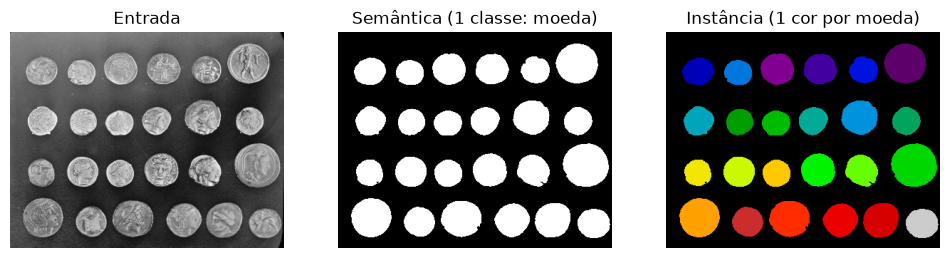

In [6]:
moedas_semantica = segmentacao_semantica(moedas, 101, -10, 500)
moedas_rotulos = segmentacao_instancia(moedas_semantica, 20)

print('Objetos conectados na máscara semântica:', cv2.connectedComponents(moedas_semantica)[0] - 1)
print('Instâncias encontradas:', moedas_rotulos.max())

mostrar([moedas, moedas_semantica, colorir_instancias(moedas_rotulos)],
        ['Entrada', 'Semântica (1 classe: moeda)', 'Instância (1 cor por moeda)'])

### Mesmo teste com outra imagem: `data.hubble_deep_field()`

Imagem do telescópio Hubble com centenas de galáxias de tamanhos, formatos e brilhos bem diferentes. Ela é colorida, então converto para cinza antes. Os parâmetros foram ajustados para a escala dos objetos (bloco menor, área mínima e distância mínima entre picos bem menores).

Objetos conectados na máscara semântica: 544
Instâncias encontradas: 620


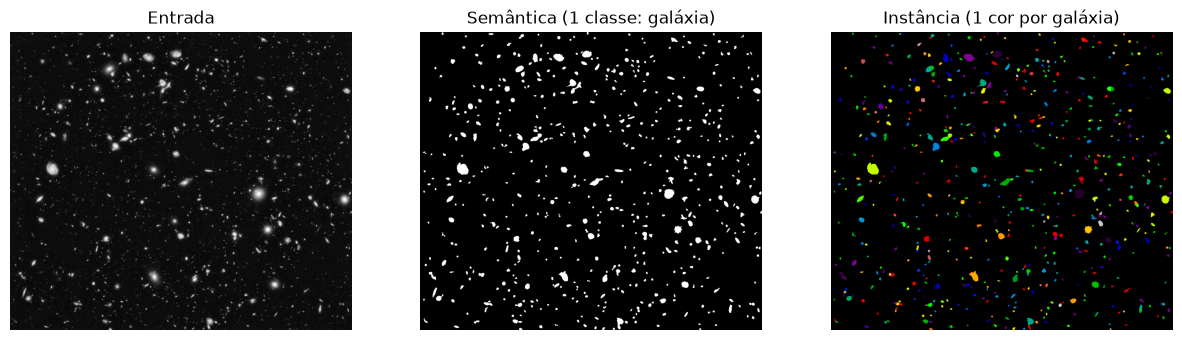

In [7]:
hubble = cv2.cvtColor(data.hubble_deep_field(), cv2.COLOR_RGB2GRAY)

hubble_semantica = segmentacao_semantica(hubble, 51, -15, 15)
hubble_rotulos = segmentacao_instancia(hubble_semantica, 4)

print('Objetos conectados na máscara semântica:', cv2.connectedComponents(hubble_semantica)[0] - 1)
print('Instâncias encontradas:', hubble_rotulos.max())

mostrar([hubble, hubble_semantica, colorir_instancias(hubble_rotulos, embaralhar=True)],
        ['Entrada', 'Semântica (1 classe: galáxia)', 'Instância (1 cor por galáxia)'], tamanho=5)

### Análise

Sim, houve diferença. Nas **moedas** a segmentação semântica e a por instância deram o mesmo resultado (24 regiões e 24 instâncias), porque as moedas são regulares, contrastam bem com o fundo e não se encostam. No **Hubble** a instância encontrou mais objetos que a semântica (544 regiões viraram 620 instâncias), porque o watershed separou galáxias que estavam grudadas na máscara. Como as galáxias variam muito de tamanho e brilho, a segmentação ficou menos precisa: galáxias fracas se perdem no ruído e as alongadas podem ser divididas a mais.